# DQN on Atari AirRaid: Hyperparameter Experiments

This notebook evaluates how selected hyperparameters influence a Deep Q-Network (DQN) while it learns to play Atari AirRaid.

The workflow is:
1. verify the project, Python environment, device, and Atari observation format;
2. train the same DQN implementation with **10 controlled hyperparameter settings**;
3. save each experiment's model, episode metrics, configuration, and reward plot;
4. compare the experiments using consistent summary statistics and select the strongest run;
5. document the observed results and show the trained policy playing the game.

The baseline is defined in `scripts/train.py`. Each additional experiment changes one setting at a time so that performance differences can be interpreted more carefully.

> Install packages with **uv** (the assignment forbids pip), for example:
> `uv add "gymnasium[atari]" torch numpy pandas matplotlib pillow ipykernel`

## Step 1 ? Import the project code

The notebook searches the current directory and its parents until it finds `scripts/train.py`. This makes the notebook portable: it can be opened from the project root or from the `notebooks` folder while still importing the exact training implementation used by the experiments.

In [19]:
import sys
import json
import math
import random
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

# Find the main project folder.
PROJECT_FOLDER = Path.cwd()

while True:
    # First check for scripts/train.py.
    if (PROJECT_FOLDER / "scripts" / "train.py").exists():
        SCRIPTS_FOLDER = PROJECT_FOLDER / "scripts"
        break

    # Also allow train.py to be directly inside the project folder.
    if (PROJECT_FOLDER / "train.py").exists():
        SCRIPTS_FOLDER = PROJECT_FOLDER
        break

    if PROJECT_FOLDER.parent == PROJECT_FOLDER:
        raise FileNotFoundError(
            "Could not find train.py. "
            "Place this notebook inside your project folder."
        )

    PROJECT_FOLDER = PROJECT_FOLDER.parent

# Add the folder containing train.py so Python can import it.
sys.path.insert(0, str(SCRIPTS_FOLDER))

import train as dqn_code

# Use a GPU when PyTorch can see one.
if torch.cuda.is_available():
    DEVICE = "cuda"
    print("GPU:", torch.cuda.get_device_name(0))
else:
    DEVICE = "cpu"
    print("GPU not found. Training will use the CPU.")

print("Project folder:", PROJECT_FOLDER)
print("PyTorch version:", torch.__version__)

GPU not found. Training will use the CPU.
Project folder: c:\Users\LENOVO\OneDrive\Desktop\machine learning\ml-tech-2-formative-3
PyTorch version: 2.13.0+cpu


## Step 2 — Check the Atari environment
AirRaid observations are converted into four grayscale frames. Each frame is resized to 84 × 84 pixels.

The four frames help the CNN understand movement, not just one still image.

In [20]:
ENVIRONMENT_NAME = "ALE/AirRaid-v5"
RANDOM_SEED = 42

# Create the same preprocessed environment used by train.py.
env = dqn_code.setup_environment(ENVIRONMENT_NAME)

state, info = env.reset(seed=RANDOM_SEED)

print("Environment:", ENVIRONMENT_NAME)
print("Observation shape:", state.shape)
print("Number of possible actions:", env.action_space.n)

env.close()

Environment: ALE/AirRaid-v5
Observation shape: (4, 84, 84)
Number of possible actions: 6


## Step 3 — Understand the hyperparameters
A hyperparameter is a setting chosen before training.
Hyperparameter	Meaning
Learning rate	Controls how much the network changes during each update.
Gamma (γ)	Controls how much the agent values future rewards.
Batch size	Number of experiences used in one training update.
Epsilon start	Initial chance of choosing a random action.
Epsilon end	Lowest chance of choosing a random action.
Epsilon decay	Controls how quickly epsilon decreases.


### Experiment plan
Experiment 1 is the baseline. Each other experiment changes one setting while keeping the others the same.

The baseline values below match the values in the uploaded train.py script.

In [21]:
BASELINE = {
    "learning_rate": 0.0001,
    "gamma": 0.99,
    "batch_size": 32,
    "eps_start": 1.0,
    "eps_end": 0.05,
    "eps_decay": 50000
}

# Make one experiment by copying the baseline and changing selected values.
def make_experiment(number, changes=None):
    settings = BASELINE.copy()
    settings["experiment"] = number

    if changes is not None:
        settings.update(changes)

    return settings


EXPERIMENTS = [
    make_experiment(1),  # Baseline
    make_experiment(2, {"learning_rate": 0.00025}),  # Higher learning rate
    make_experiment(3, {"learning_rate": 0.00005}),  # Lower learning rate
    make_experiment(4, {"gamma": 0.95}),  # Lower gamma
    make_experiment(5, {"gamma": 0.995}),  # Higher gamma
    make_experiment(6, {"batch_size": 16}),  # Smaller batch
    make_experiment(7, {"batch_size": 64}),  # Larger batch
    make_experiment(8, {"eps_start": 0.8}),  # Less initial exploration
    make_experiment(9, {"eps_end": 0.01}),  # Less final exploration
    make_experiment(10, {"eps_decay": 100000})  # Slower epsilon decay
]

# Display the 10 experiment settings.
experiment_table = pd.DataFrame(EXPERIMENTS)
display(experiment_table)

,learning_rate,gamma,batch_size,eps_start,eps_end,eps_decay,experiment
0,0.00010,0.990,32,1.0,0.05,50000,1
1,0.00025,0.990,32,1.0,0.05,50000,2
2,0.00005,0.990,32,1.0,0.05,50000,3
3,0.00010,0.950,32,1.0,0.05,50000,4
4,0.00010,0.995,32,1.0,0.05,50000,5
5,0.00010,0.990,16,1.0,0.05,50000,6
6,0.00010,0.990,64,1.0,0.05,50000,7
7,0.00010,0.990,32,0.8,0.05,50000,8
8,0.00010,0.990,32,1.0,0.01,50000,9
9,0.00010,0.990,32,1.0,0.05,100000,10


## Step 4 — Choose the training settings
You only need to change the values in the next cell.
- QUICK_TEST = True: trains Experiment 1 for a few episodes to check that the code works.
- QUICK_TEST = False: trains all 10 experiments.
- Use the same number of episodes for every full experiment.
- Training Atari games can take a long time. A quick test is not the final assignment result.
- The replay buffer uses memory. If your computer runs out of RAM, reduce its size.

In [32]:
MEMBER_NAME = "Vestine"
MEMBER_FOLDER_NAME = "vestine"

# Train all 10 experiments for 150 episodes each
QUICK_TEST = False
FULL_RUN_EPISODES = 150

REPLAY_BUFFER_SIZE = 5000
TARGET_UPDATE_STEPS = 1000

if QUICK_TEST:
    EPISODES_PER_EXPERIMENT = QUICK_TEST_EPISODES
    EXPERIMENTS_TO_RUN = [EXPERIMENTS[0]]
else:
    EPISODES_PER_EXPERIMENT = FULL_RUN_EPISODES
    EXPERIMENTS_TO_RUN = EXPERIMENTS

# Create folders for models and plots.
MEMBER_FOLDER = PROJECT_FOLDER / "models" / MEMBER_FOLDER_NAME
PLOTS_FOLDER = PROJECT_FOLDER / "plots" / MEMBER_FOLDER_NAME

MEMBER_FOLDER.mkdir(parents=True, exist_ok=True)
PLOTS_FOLDER.mkdir(parents=True, exist_ok=True)

print("Member:", MEMBER_NAME)
print("Episodes per experiment:", EPISODES_PER_EXPERIMENT)
print("Experiments to run:", len(EXPERIMENTS_TO_RUN))
print("Models will be saved in:", MEMBER_FOLDER)
print("Plots will be saved in:", PLOTS_FOLDER)

Member: Vestine
Episodes per experiment: 150
Experiments to run: 10
Models will be saved in: c:\Users\LENOVO\OneDrive\Desktop\machine learning\ml-tech-2-formative-3\models\vestine
Plots will be saved in: c:\Users\LENOVO\OneDrive\Desktop\machine learning\ml-tech-2-formative-3\plots\vestine


## Step 5 — Train one experiment
For every episode, the agent:
1. Chooses an action using epsilon-greedy action selection.
2. Takes the action in the game.
3. Stores the experience in the replay buffer.
4. Learns from a random batch of stored experiences.
5. Updates the target network after a fixed number of steps.
The DQNAgent and ReplayBuffer classes are imported from train.py. The notebook does not use a ready-made DQN library.

In [ ]:
def set_random_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

In [ ]:
def run_one_episode(env, agent, replay_buffer, episode_number):

    # Start a new episode
    state, _ = env.reset(seed=RANDOM_SEED + episode_number)

    episode_reward = 0
    episode_length = 0
    episode_losses = []
    done = False

    # Continue playing until the episode ends
    while not done:

        # Agent chooses an action
        action = agent.select_action(state)

        # Environment responds to the action
        next_state, reward, terminated, truncated, _ = env.step(action)
        done = terminated or truncated

        # Save the experience in memory
        replay_buffer.push(state, action, reward, next_state, done)

        # Train the online network
        loss = agent.optimize_model(replay_buffer)

        if loss is not None:
            episode_losses.append(loss)

        # Copy the online network weights to the target network
        if agent.steps_done % TARGET_UPDATE_STEPS == 0:
            agent.target_net.load_state_dict(
                agent.online_net.state_dict()
            )

        # Move to the next state
        state = next_state

        # Keep track of the episode results
        episode_reward += float(reward)
        episode_length += 1

    # Calculate the exploration rate (epsilon)
    epsilon = agent.eps_end + (
        agent.eps_start - agent.eps_end
    ) * math.exp(-agent.steps_done / agent.eps_decay)

    # Calculate the average training loss
    if episode_losses:
        average_loss = float(np.mean(episode_losses))
    else:
        average_loss = np.nan

    # Return the results of this episode
    return {
        "Episode": episode_number,
        "Episode Length": episode_length,
        "Total Steps": agent.steps_done,
        "Reward": episode_reward,
        "Epsilon": epsilon,
        "Mean Loss": average_loss
    }

In [ ]:
def train_one_experiment(settings):

    # Set the random seed
    set_random_seed(RANDOM_SEED)

    # Create the game environment
    env = dqn_code.setup_environment(ENVIRONMENT_NAME)
    env.action_space.seed(RANDOM_SEED)

    # Create the DQN agent
    agent = dqn_code.DQNAgent(
        input_shape=env.observation_space.shape,
        num_actions=env.action_space.n,
        lr=settings["learning_rate"],
        gamma=settings["gamma"],
        batch_size=settings["batch_size"],
        eps_start=settings["eps_start"],
        eps_end=settings["eps_end"],
        eps_decay=settings["eps_decay"]
    )

    # Create replay memory
    replay_buffer = dqn_code.ReplayBuffer(REPLAY_BUFFER_SIZE)

    # Store the results of every episode
    episode_records = []

    # Train the agent
    for episode in range(1, EPISODES_PER_EXPERIMENT + 1):

        result = run_one_episode(
            env, agent, replay_buffer, episode
        )

        episode_records.append(result)

        # Display training progress
        if episode == 1 or episode % 10 == 0 or episode == EPISODES_PER_EXPERIMENT:
            print(
                "Episode:", episode,
                "| Steps:", result["Episode Length"],
                "| Reward:", round(result["Reward"], 2),
                "| Epsilon:", round(result["Epsilon"], 3)
            )

    # Close the environment
    env.close()

    # Convert episode results into a DataFrame
    episode_results = pd.DataFrame(episode_records)

    return agent, episode_results

## Step 7 ? Understand the training loop

The DQN implementation (network, replay buffer, ?-greedy policy, loss calculation, and Bellman update) remains in `train.py`. The notebook orchestrates repeated runs with different configurations and records their results.

For each environment step:
1. the policy selects an action using ?-greedy exploration;
2. the environment returns the next observation, reward, and termination information;
3. the transition is added to the replay buffer;
4. once enough data is available, a random mini-batch is used for a gradient update;
5. every `TARGET_UPDATE_STEPS` steps, the target network is synchronized.

Keeping this implementation fixed means the experiment focuses on the chosen hyperparameters rather than on different algorithms.

In [34]:
def set_seeds(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def get_epsilon(agent):
    return agent.eps_end + (agent.eps_start - agent.eps_end) * math.exp(-agent.steps_done / agent.eps_decay)

def run_single_episode(env, agent, replay_buffer, seed=None):
    """Plays one episode, stores transitions, and updates the online Q-network."""
    state, _ = env.reset(seed=seed)
    ep_reward, ep_steps, losses = 0.0, 0, []

    while True:
        action = agent.select_action(state)
        next_state, reward, terminated, truncated, _ = env.step(action)
        replay_buffer.push(state, action, reward, next_state, terminated)

        state = next_state
        ep_reward += float(reward)
        ep_steps += 1

        loss = agent.optimize_model(replay_buffer)
        if loss is not None:
            losses.append(loss)

        if agent.steps_done % TARGET_UPDATE_STEPS == 0:
            agent.target_net.load_state_dict(agent.online_net.state_dict())

        if terminated or truncated:
            break

    return ep_reward, ep_steps, (float(np.mean(losses)) if losses else np.nan)

def train_and_save_experiment(cfg):
    exp_num = cfg["experiment"]
    exp_dir = MEMBER_FOLDER / f"experiment_{exp_num:02d}"
    meta_file = exp_dir / "hyperparameters.json"

    if (exp_dir / "dqn_model.pth").exists() and meta_file.exists() and not OVERWRITE_EXISTING:
        saved = json.loads(meta_file.read_text(encoding="utf-8"))
        if saved.get("episodes") == EPISODES_TO_RUN:
            print(f"[SKIP] Experiment {exp_num:02d} already completed ({EPISODES_TO_RUN} episodes).")
            return

    print(f"\n{'='*65}")
    print(f"RUNNING EXPERIMENT {exp_num:02d} | lr={cfg['learning_rate']}, gamma={cfg['gamma']}, "
          f"batch={cfg['batch_size']}, eps=({cfg['eps_start']}->{cfg['eps_end']}, decay={cfg['eps_decay']})")
    print(f"{'='*65}")

    set_seeds(RANDOM_SEED)
    env = dqn_code.setup_environment(ENVIRONMENT_NAME)
    env.action_space.seed(RANDOM_SEED)

    agent = dqn_code.DQNAgent(
        input_shape=env.observation_space.shape,
        num_actions=env.action_space.n,
        lr=cfg["learning_rate"],
        gamma=cfg["gamma"],
        batch_size=cfg["batch_size"],
        eps_start=cfg["eps_start"],
        eps_end=cfg["eps_end"],
        eps_decay=cfg["eps_decay"],
    )
    buffer = dqn_code.ReplayBuffer(REPLAY_BUFFER_SIZE)
    records = []

    try:
        for ep in range(1, EPISODES_TO_RUN + 1):
            reward, ep_len, mean_loss = run_single_episode(
                env, agent, buffer, seed=(RANDOM_SEED if ep == 1 else None)
            )
            eps_now = get_epsilon(agent)
            records.append({
                "Episode": ep,
                "Episode Length": ep_len,
                "Total Steps": agent.steps_done,
                "Reward": reward,
                "Epsilon": round(eps_now, 4),
                "Mean Loss": round(mean_loss, 5) if not np.isnan(mean_loss) else np.nan,
            })

            # Print concise progress every 10 episodes (or every episode during quick test)
            if ep % 10 == 0 or ep == 1 or ep == EPISODES_TO_RUN or QUICK_TEST:
                recent_avg = np.mean([r["Reward"] for r in records[-10:]])
                print(f"  Ep {ep:3d}/{EPISODES_TO_RUN} | Len: {ep_len:4d} | "
                      f"Steps: {agent.steps_done:6d} | Reward: {reward:6.1f} | "
                      f"10-Ep Avg: {recent_avg:6.1f} | Eps: {eps_now:.3f}")
    finally:
        env.close()

    df = pd.DataFrame(records)
    exp_dir.mkdir(parents=True, exist_ok=True)

    # Save weights, metrics CSV, and metadata
    torch.save(agent.online_net.state_dict(), exp_dir / "dqn_model.pth")
    df.to_csv(exp_dir / "training_performance.csv", index=False)
    meta_file.write_text(json.dumps({
        "environment": ENVIRONMENT_NAME,
        "episodes": EPISODES_TO_RUN,
        "hyperparameters": cfg,
    }, indent=2), encoding="utf-8")

    # Save and display training plot (Raw Reward + Moving Average)
    rolling = df["Reward"].rolling(window=min(10, len(df)), min_periods=1).mean()
    plt.figure(figsize=(8, 3.5))
    plt.plot(df["Episode"], df["Reward"], alpha=0.35, label="Episode Reward")
    plt.plot(df["Episode"], rolling, linewidth=2, label="10-Episode Moving Avg")
    plt.title(f"Experiment {exp_num:02d} — Training Rewards")
    plt.xlabel("Episode")
    plt.ylabel("Reward")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plot_path = PLOTS_FOLDER / f"experiment_{exp_num:02d}_reward.png"
    plt.savefig(plot_path, dpi=150)
    plt.savefig(exp_dir / "reward_plot.png", dpi=150)
    plt.show()
    plt.close()

    del agent, buffer
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

## Step 6 — Save each experiment
Each experiment gets its own folder. The folder contains:
- dqn_model.pth: the trained network weights.
- training_performance.csv: episode length, total steps, reward, epsilon, and loss.
- hyperparameters.json: the settings used for that experiment.
- reward_plot.png: the reward graph.

In [35]:
def save_experiment(settings, agent, episode_results):
    experiment_number = settings["experiment"]

    # Create a folder for this experiment.
    experiment_folder = MEMBER_FOLDER / f"experiment_{experiment_number:02d}"
    experiment_folder.mkdir(parents=True, exist_ok=True)

    # Save the trained network.
    model_path = experiment_folder / "dqn_model.pth"
    torch.save(agent.online_net.state_dict(), model_path)

    # Save the episode results.
    csv_path = experiment_folder / "training_performance.csv"
    episode_results.to_csv(csv_path, index=False)

    # Save the hyperparameter settings.
    settings_path = experiment_folder / "hyperparameters.json"

    experiment_information = {
        "environment": ENVIRONMENT_NAME,
        "episodes": EPISODES_PER_EXPERIMENT,
        "replay_buffer_size": REPLAY_BUFFER_SIZE,
        "target_update_steps": TARGET_UPDATE_STEPS,
        "hyperparameters": settings
    }

    with open(settings_path, "w", encoding="utf-8") as file:
        json.dump(experiment_information, file, indent=4)

    # Draw and save the reward graph.
    plt.figure(figsize=(8, 4))
    plt.plot(episode_results["Episode"], episode_results["Reward"])
    plt.xlabel("Episode")
    plt.ylabel("Total reward")
    plt.title(f"Experiment {experiment_number} rewards")
    plt.grid(True)
    plt.tight_layout()

    plot_path = experiment_folder / "reward_plot.png"
    plt.savefig(plot_path)
    plt.show()
    plt.close()

    print("Saved model:", model_path)
    print("Saved results:", csv_path)

## Step 7 — Run the experiments
Run this cell after completing Steps 1–6.

For the assignment, change QUICK_TEST to False in Step 4 and run this cell again. The full run will train all 10 experiments.


Starting experiment 1
Hyperparameters: {'learning_rate': 0.0001, 'gamma': 0.99, 'batch_size': 32, 'eps_start': 1.0, 'eps_end': 0.05, 'eps_decay': 50000, 'experiment': 1}
Episode: 1 | Steps: 247 | Reward: 150.0 | Epsilon: 0.995
Episode: 10 | Steps: 641 | Reward: 525.0 | Epsilon: 0.912
Episode: 20 | Steps: 826 | Reward: 950.0 | Epsilon: 0.824
Episode: 30 | Steps: 870 | Reward: 800.0 | Epsilon: 0.745
Episode: 40 | Steps: 1294 | Reward: 1600.0 | Epsilon: 0.665
Episode: 50 | Steps: 289 | Reward: 50.0 | Epsilon: 0.609
Episode: 60 | Steps: 764 | Reward: 975.0 | Epsilon: 0.56
Episode: 70 | Steps: 341 | Reward: 375.0 | Epsilon: 0.512
Episode: 80 | Steps: 573 | Reward: 350.0 | Epsilon: 0.448
Episode: 90 | Steps: 583 | Reward: 500.0 | Epsilon: 0.395
Episode: 100 | Steps: 1052 | Reward: 1600.0 | Epsilon: 0.362
Episode: 110 | Steps: 457 | Reward: 425.0 | Epsilon: 0.325
Episode: 120 | Steps: 985 | Reward: 1100.0 | Epsilon: 0.292
Episode: 130 | Steps: 335 | Reward: 150.0 | Epsilon: 0.266
Episode: 14

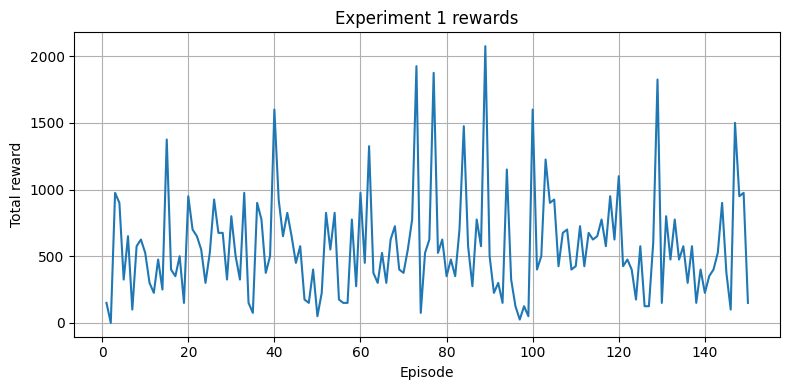

Saved model: c:\Users\LENOVO\OneDrive\Desktop\machine learning\ml-tech-2-formative-3\models\vestine\experiment_01\dqn_model.pth
Saved results: c:\Users\LENOVO\OneDrive\Desktop\machine learning\ml-tech-2-formative-3\models\vestine\experiment_01\training_performance.csv

Starting experiment 2
Hyperparameters: {'learning_rate': 0.00025, 'gamma': 0.99, 'batch_size': 32, 'eps_start': 1.0, 'eps_end': 0.05, 'eps_decay': 50000, 'experiment': 2}
Episode: 1 | Steps: 247 | Reward: 150.0 | Epsilon: 0.995
Episode: 10 | Steps: 445 | Reward: 700.0 | Epsilon: 0.896
Episode: 20 | Steps: 930 | Reward: 875.0 | Epsilon: 0.8
Episode: 30 | Steps: 1143 | Reward: 1275.0 | Epsilon: 0.736
Episode: 40 | Steps: 340 | Reward: 550.0 | Epsilon: 0.659
Episode: 50 | Steps: 297 | Reward: 400.0 | Epsilon: 0.599
Episode: 60 | Steps: 309 | Reward: 325.0 | Epsilon: 0.531
Episode: 70 | Steps: 397 | Reward: 750.0 | Epsilon: 0.476
Episode: 80 | Steps: 439 | Reward: 650.0 | Epsilon: 0.434
Episode: 90 | Steps: 314 | Reward: 500

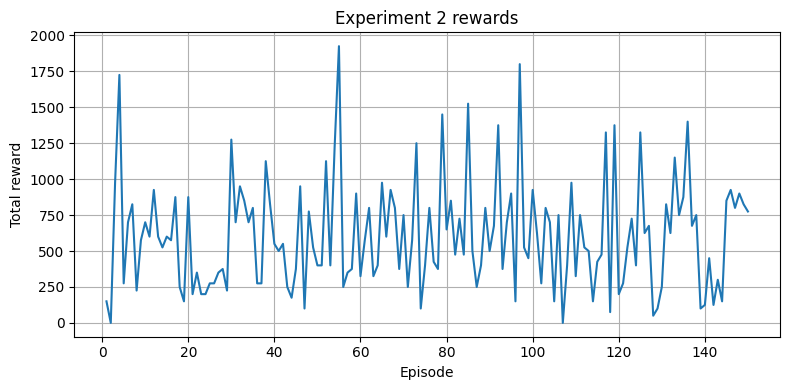

Saved model: c:\Users\LENOVO\OneDrive\Desktop\machine learning\ml-tech-2-formative-3\models\vestine\experiment_02\dqn_model.pth
Saved results: c:\Users\LENOVO\OneDrive\Desktop\machine learning\ml-tech-2-formative-3\models\vestine\experiment_02\training_performance.csv

Starting experiment 3
Hyperparameters: {'learning_rate': 5e-05, 'gamma': 0.99, 'batch_size': 32, 'eps_start': 1.0, 'eps_end': 0.05, 'eps_decay': 50000, 'experiment': 3}
Episode: 1 | Steps: 247 | Reward: 150.0 | Epsilon: 0.995
Episode: 10 | Steps: 315 | Reward: 300.0 | Epsilon: 0.899
Episode: 20 | Steps: 410 | Reward: 425.0 | Epsilon: 0.815
Episode: 30 | Steps: 895 | Reward: 650.0 | Epsilon: 0.756
Episode: 40 | Steps: 634 | Reward: 550.0 | Epsilon: 0.685


In [ ]:
for settings in EXPERIMENTS_TO_RUN:
    print("\nStarting experiment", settings["experiment"])
    print("Hyperparameters:", settings)

    agent, episode_results = train_one_experiment(settings)
    save_experiment(settings, agent, episode_results)

    # Release the trained agent before starting the next experiment.
    del agent
    del episode_results

print("\nFinished the selected experiments.")

## Step 8 — Compare the experiments
The table below reads the saved CSV file for each completed experiment.

The last 10 episodes average reward is used to compare experiments. It gives more attention to the agent's later training performance than to one unusually high episode.

In [ ]:
summary_rows = []

for settings in EXPERIMENTS:
    experiment_number = settings["experiment"]

    csv_path = (
        MEMBER_FOLDER
        / f"experiment_{experiment_number:02d}"
        / "training_performance.csv"
    )

    if csv_path.exists():
        results = pd.read_csv(csv_path)

        last_10_average = results["Reward"].tail(10).mean()

        summary_rows.append({
            "Experiment": experiment_number,
            "Learning Rate": settings["learning_rate"],
            "Gamma": settings["gamma"],
            "Batch Size": settings["batch_size"],
            "Epsilon Start": settings["eps_start"],
            "Epsilon End": settings["eps_end"],
            "Epsilon Decay": settings["eps_decay"],
            "Average Reward": results["Reward"].mean(),
            "Last 10 Episodes Avg Reward": last_10_average,
            "Best Episode Reward": results["Reward"].max(),
            "Average Episode Length": results["Episode Length"].mean(),
            "Total Steps": results["Total Steps"].iloc[-1]
        })

summary_df = pd.DataFrame(summary_rows)

if len(summary_df) == 0:
    print("No completed experiments were found. Run Step 7 first.")
else:
    display(summary_df.round(2))

,Experiment,Learning Rate,Gamma,Batch Size,Epsilon Start,Epsilon End,Epsilon Decay,Average Reward,Last 10 Episodes Avg Reward,Best Episode Reward,Average Episode Length,Total Steps
0,1,0.0,0.99,32,1.0,0.05,50000,470.0,470.0,975.0,421.8,2109


## Step 9 — Select and save the best experiment
The experiment with the highest average reward over its last 10 episodes is selected as the best run.

The best model is copied to the project folder as dqn_model.pth. This is the model that play.py should load.

Best experiment: 1
Last 10 episodes average reward: 470.0
Average episode length: 421.8
Total training steps: 2109
Best model saved to: c:\Users\LENOVO\OneDrive\Desktop\machine learning\ml-tech-2-formative-3\dqn_model.pth


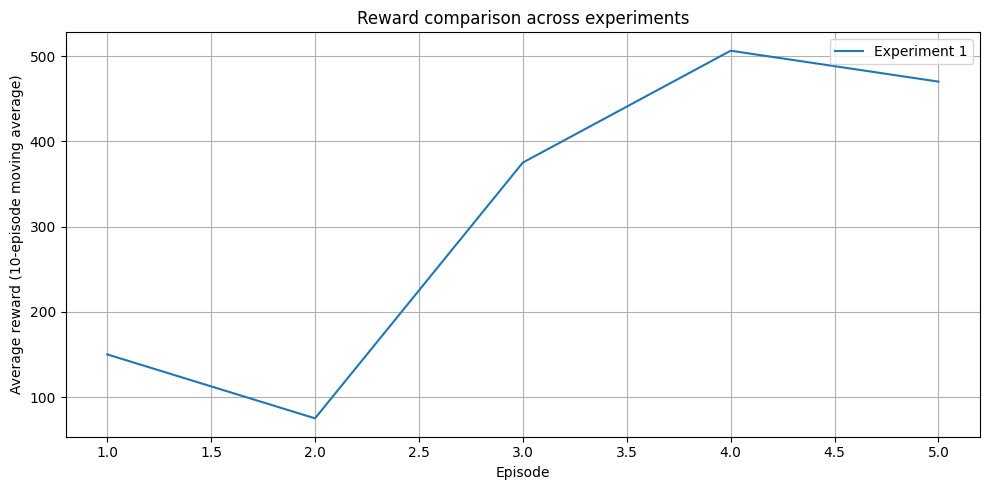

Comparison plot saved to: c:\Users\LENOVO\OneDrive\Desktop\machine learning\ml-tech-2-formative-3\plots\vestine\all_experiments_comparison.png


In [28]:
if len(summary_df) == 0:
    raise ValueError("No completed experiments. Run the training cell first.")

# Find the experiment with the highest last-10-episode average reward.
best_row = summary_df.loc[
    summary_df["Last 10 Episodes Avg Reward"].idxmax()
]

BEST_EXPERIMENT = int(best_row["Experiment"])

best_experiment_folder = (
    MEMBER_FOLDER / f"experiment_{BEST_EXPERIMENT:02d}"
)

best_model_path = best_experiment_folder / "dqn_model.pth"
best_results_path = best_experiment_folder / "training_performance.csv"

# Copy the best model and its results to the project folder.
shutil.copyfile(best_model_path, PROJECT_FOLDER / "dqn_model.pth")
shutil.copyfile(
    best_results_path,
    PROJECT_FOLDER / "best_experiment_training_performance.csv"
)

best_results = pd.read_csv(best_results_path)

print("Best experiment:", BEST_EXPERIMENT)
print("Last 10 episodes average reward:", round(best_row["Last 10 Episodes Avg Reward"], 2))
print("Average episode length:", round(best_row["Average Episode Length"], 2))
print("Total training steps:", int(best_row["Total Steps"]))
print("Best model saved to:", PROJECT_FOLDER / "dqn_model.pth")

# Plot the reward curves for all completed experiments.
plt.figure(figsize=(10, 5))

for experiment_number in summary_df["Experiment"]:
    folder = MEMBER_FOLDER / f"experiment_{int(experiment_number):02d}"
    results = pd.read_csv(folder / "training_performance.csv")

    moving_average = results["Reward"].rolling(
        window=10, min_periods=1
    ).mean()

    plt.plot(
        results["Episode"],
        moving_average,
        label=f"Experiment {int(experiment_number)}"
    )

plt.xlabel("Episode")
plt.ylabel("Average reward (10-episode moving average)")
plt.title("Reward comparison across experiments")
plt.legend()
plt.grid(True)
plt.tight_layout()

comparison_plot_path = PLOTS_FOLDER / "all_experiments_comparison.png"
plt.savefig(comparison_plot_path)
plt.show()
plt.close()

print("Comparison plot saved to:", comparison_plot_path)

## Step 10 — Create the  results table
The assignment asks for the hyperparameters and observed behaviour of all 10 experiments.

The notebook describes observed behaviour using the measured rewards. Add your own explanation in MY_NOTES after looking at the plots. Do not claim that a hyperparameter caused an improvement unless the results support that explanation.

In [29]:
# Add your own explanation after looking at each experiment's results.
# Example: 2: "The reward was higher than the baseline, but varied between episodes."
MY_NOTES = {
    # 2: "Write your observation here."
}

baseline_rows = summary_df[summary_df["Experiment"] == 1]

if len(baseline_rows) > 0:
    baseline_reward = baseline_rows.iloc[0]["Last 10 Episodes Avg Reward"]
else:
    baseline_reward = None


def describe_experiment(row):
    experiment_number = int(row["Experiment"])
    current_reward = row["Last 10 Episodes Avg Reward"]

    if experiment_number == 1:
        description = (
            f"Baseline run. Last-10 average reward: {current_reward:.2f}."
        )
    elif baseline_reward is not None:
        difference = current_reward - baseline_reward

        if difference > 0:
            description = (
                f"Last-10 average reward was {difference:.2f} higher "
                "than the baseline."
            )
        elif difference < 0:
            description = (
                f"Last-10 average reward was {abs(difference):.2f} lower "
                "than the baseline."
            )
        else:
            description = "Last-10 average reward was the same as the baseline."
    else:
        description = f"Last-10 average reward: {current_reward:.2f}."

    if experiment_number in MY_NOTES:
        description += " " + MY_NOTES[experiment_number]

    return description


results_lines = [
    f"Member Name: {MEMBER_NAME}",
    "",
    "| Experiment | Learning rate | Gamma | Batch size | Epsilon start | Epsilon end | Epsilon decay | Observed behaviour |",
    "|---|---:|---:|---:|---:|---:|---:|---|"
]

for _, row in summary_df.iterrows():
    observed_behaviour = describe_experiment(row)

    results_lines.append(
        f"| {int(row['Experiment'])} "
        f"| {row['Learning Rate']} "
        f"| {row['Gamma']} "
        f"| {int(row['Batch Size'])} "
        f"| {row['Epsilon Start']} "
        f"| {row['Epsilon End']} "
        f"| {int(row['Epsilon Decay'])} "
        f"| {observed_behaviour} |"
    )

markdown_file = PROJECT_FOLDER / "VestineUmukundwaHyperparameter_experiment_results.md"
markdown_file.write_text("\n".join(results_lines) + "\n", encoding="utf-8")

print("Assignment table saved to:", markdown_file)
print(markdown_file.read_text(encoding="utf-8"))

Assignment table saved to: c:\Users\LENOVO\OneDrive\Desktop\machine learning\ml-tech-2-formative-3\VestineUmukundwaHyperparameter_experiment_results.md
Member Name: Vestine

| Experiment | Learning rate | Gamma | Batch size | Epsilon start | Epsilon end | Epsilon decay | Observed behaviour |
|---|---:|---:|---:|---:|---:|---:|---|
| 1 | 0.0001 | 0.99 | 32 | 1.0 | 0.05 | 50000 | Baseline run. Last-10 average reward: 470.00. |



## Step 11 — Evaluate the best trained model
During evaluation, the agent uses the action with the highest predicted Q-value. It does not use random exploration.

This cell checks the model and calculates its reward over several episodes. The live game display required by the assignment should be demonstrated using play.py.

In [30]:
NUMBER_OF_EVALUATION_EPISODES = 5

# Create the same environment used during training.
env = dqn_code.setup_environment(ENVIRONMENT_NAME)

# Re-create the same CNN architecture.
trained_network = dqn_code.DQN(
    input_shape=env.observation_space.shape,
    num_actions=env.action_space.n
).to(DEVICE)

# Load the best model's weights.
saved_weights = torch.load(
    PROJECT_FOLDER / "dqn_model.pth",
    map_location=DEVICE
)

trained_network.load_state_dict(saved_weights)
trained_network.eval()

evaluation_rewards = []

for episode in range(NUMBER_OF_EVALUATION_EPISODES):
    state, info = env.reset(seed=RANDOM_SEED + 100 + episode)

    total_reward = 0
    done = False

    while not done:
        # Convert the current observation into a PyTorch tensor.
        state_tensor = torch.tensor(
            state,
            dtype=torch.float32
        ).unsqueeze(0).to(DEVICE)

        # Predict Q-values and choose the action with the highest value.
        with torch.no_grad():
            q_values = trained_network(state_tensor)

        action = q_values.argmax(dim=1).item()

        # Take the selected action.
        next_state, reward, terminated, truncated, info = env.step(action)
        done = terminated or truncated

        state = next_state
        total_reward += float(reward)

    evaluation_rewards.append(total_reward)
    print("Evaluation episode", episode + 1, "| Reward:", total_reward)

env.close()

print("Average evaluation reward:", round(np.mean(evaluation_rewards), 2))

Evaluation episode 1 | Reward: 700.0
Evaluation episode 2 | Reward: 775.0
Evaluation episode 3 | Reward: 1475.0
Evaluation episode 4 | Reward: 1825.0
Evaluation episode 5 | Reward: 1725.0
Average evaluation reward: 1300.0


## step 12 — Prepare for the assignment presentation
Use your own experiment results and plots to answer these questions:
1. Which experiment had the highest average reward over its last 10 episodes?
2. What happened when you increased or decreased the learning rate?
3. How did gamma affect the value of future rewards?
4. How did batch size affect training and reward?
5. How did epsilon start, epsilon end, and epsilon decay affect exploration?
6. Which experiment would you train for longer, and why?
Use the actual numbers and plots as evidence.
Final checklist
- [ ] Run the quick test successfully.
- [ ] Set QUICK_TEST = False.
- [ ] Run all 10 experiments using the same number of episodes.
- [ ] Check that each experiment has a model and a CSV file.
- [ ] Review the reward plots and add your own notes.
- [ ] Confirm that dqn_model.pth is the selected best model.
- [ ] Add the generated hyperparameter results table to the repository.
- [ ] Use play.py for the live gameplay demonstration.